In [1]:
# ==============================================================================
# NOTEBOOK 05: TRẢ LỜI CÂU HỎI NGHIỆP VỤ (Q1 & Q2) BẰNG DATA MINING
# ==============================================================================
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
import os

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

tables_dir = Path("reports/tables")
figs_dir = Path("reports/figures")
print("✅ Sẵn sàng trình diễn Câu hỏi nghiệp vụ!")

✅ Sẵn sàng trình diễn Câu hỏi nghiệp vụ!


🔍 CÂU HỎI 1: ĐẶC TRƯNG NÀO PHÂN BIỆT RÕ NHẤT DDoS VÀ TRAFFIC BÌNH THƯỜNG?

Bảng xếp hạng độ quan trọng của các đặc trưng (Top 10):


,rank,feature,univariate_auc,direction,perm_importance_mean
0,1,dst_port,0.478027,như nhau,0.021932
1,2,fwd_packet_length_max,0.250626,DDoS thấp hơn,0.012366
2,3,fwd_iat_mean,0.782729,DDoS cao hơn,0.000236
3,4,init_win_bytes_backward,0.580038,DDoS cao hơn,0.000202
4,5,init_win_bytes_forward,0.687591,DDoS cao hơn,0.000101
5,6,bwd_packet_length_min,0.221495,DDoS thấp hơn,0.000101
6,7,bwd_packets_per_s,0.277260,DDoS thấp hơn,0.000101
7,8,fwd_packet_length_mean,0.253850,DDoS thấp hơn,0.000067
8,9,bwd_packet_length_max,0.678929,DDoS cao hơn,0.000067
9,10,fwd_iat_std,0.814082,DDoS cao hơn,0.000034


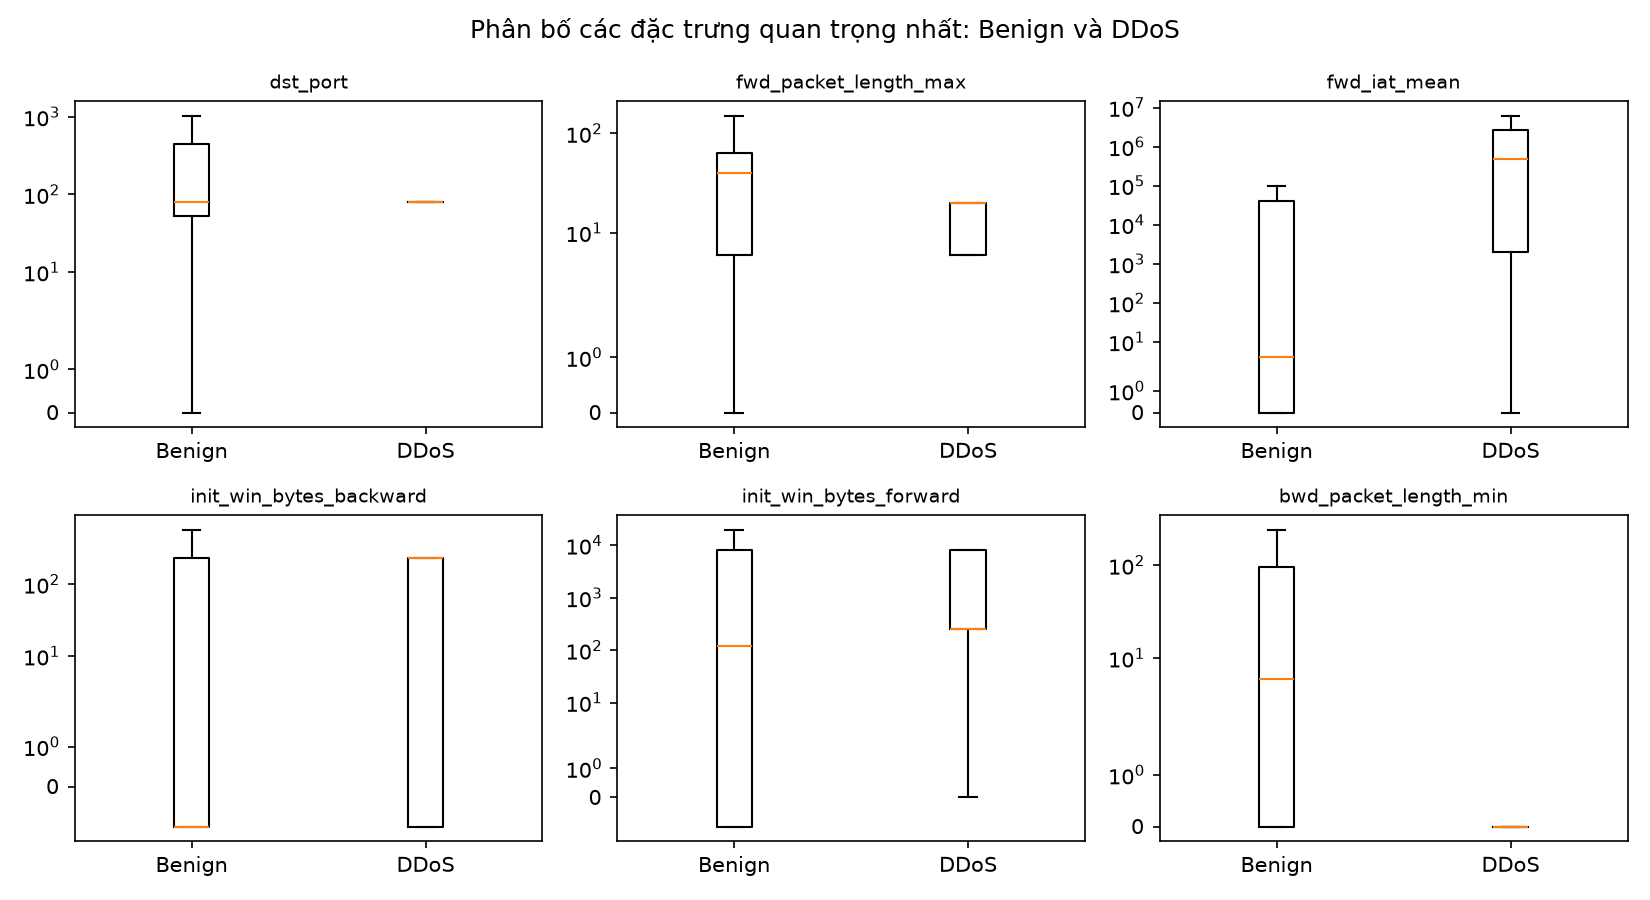


🌳 Cây quyết định trích xuất luật nhận diện nhanh DDoS:
Cây quyết định độ sâu 3 (Benign=0, DDoS=1), phạm vi Benign: all
F1 trên tập test: 0.9991

|--- fwd_packet_length_max <= 21.00
|   |--- total_fwd_bytes <= 19.00
|   |   |--- max_packet_length <= 480.50
|   |   |   |--- class: 0
|   |   |--- max_packet_length >  480.50
|   |   |   |--- class: 1
|   |--- total_fwd_bytes >  19.00
|   |   |--- dst_port <= 109.50
|   |   |   |--- class: 1
|   |   |--- dst_port >  109.50
|   |   |   |--- class: 0
|--- fwd_packet_length_max >  21.00
|   |--- class: 0



In [2]:
print("🔍 CÂU HỎI 1: ĐẶC TRƯNG NÀO PHÂN BIỆT RÕ NHẤT DDoS VÀ TRAFFIC BÌNH THƯỜNG?")
q1_csv = tables_dir / "q1_feature_ranking_all.csv"

if q1_csv.exists():
    df_q1 = pd.read_csv(q1_csv)
    print("\nBảng xếp hạng độ quan trọng của các đặc trưng (Top 10):")
    display(df_q1[['rank', 'feature', 'univariate_auc', 'direction', 'perm_importance_mean']].head(10))
    
    q1_img = figs_dir / "q1_top_features_all.png"
    if q1_img.exists():
        display(Image(filename=str(q1_img), width=900))
        
    # In luật của Cây quyết định
    q1_rules = tables_dir / "q1_tree_rules_all.txt"
    if q1_rules.exists():
        print("\n🌳 Cây quyết định trích xuất luật nhận diện nhanh DDoS:")
        print(q1_rules.read_text(encoding="utf-8"))
else:
    print("⚠️ Chưa có kết quả Q1. Hãy chạy `python -m src.mining.business_questions`.")

🤖 CÂU HỎI 2: ĐỊA CHỈ IP NÀO CÓ HÀNH VI GIỐNG MẠNG MÁY TÍNH MA (BOTNET) NHẤT?

Top 10 IP đáng ngờ nhất dựa trên thuật toán phân cụm hành vi (KMeans):


,botlike_rank,src_ip,dist_to_bot_profile,n_flows,is_known_bot
0,1,192.168.10.16,1.762553,122052,False
1,2,192.168.10.12,1.899377,146252,True
2,3,192.168.10.5,1.951460,170095,True
3,4,192.168.10.9,2.216710,152532,True
4,5,192.168.10.17,2.359985,123183,True
5,6,192.168.10.19,2.551512,115781,False
6,7,192.168.10.51,2.564520,77122,False
7,8,192.168.10.14,2.565796,140974,True
8,9,192.168.10.15,2.922371,146028,True
9,10,192.168.10.8,3.460067,215135,True



Biểu đồ phân cụm không gian hành vi IP (PCA Projection):


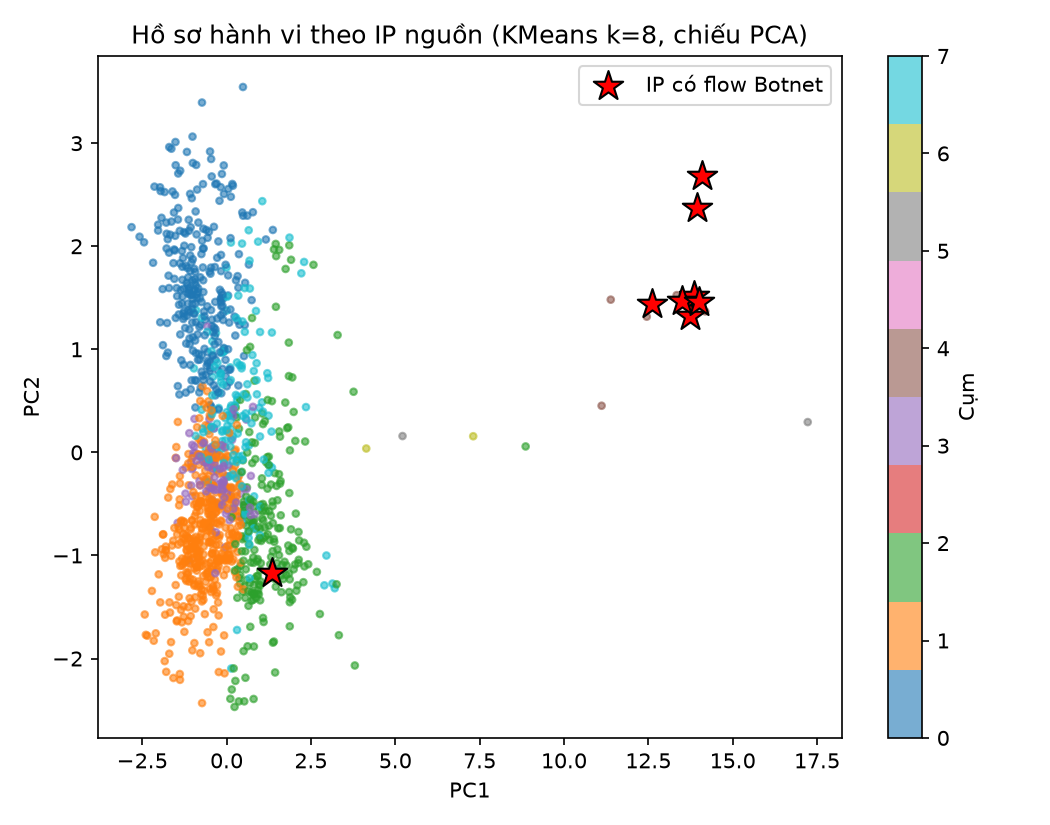

In [3]:
print("🤖 CÂU HỎI 2: ĐỊA CHỈ IP NÀO CÓ HÀNH VI GIỐNG MẠNG MÁY TÍNH MA (BOTNET) NHẤT?")
q2_csv = tables_dir / "q2_botlike_ranking.csv"

if q2_csv.exists():
    df_q2 = pd.read_csv(q2_csv)
    print("\nTop 10 IP đáng ngờ nhất dựa trên thuật toán phân cụm hành vi (KMeans):")
    display(df_q2[['botlike_rank', 'src_ip', 'dist_to_bot_profile', 'n_flows', 'is_known_bot']].head(10))
    
    q2_img = figs_dir / "q2_ip_clusters.png"
    if q2_img.exists():
        print("\nBiểu đồ phân cụm không gian hành vi IP (PCA Projection):")
        display(Image(filename=str(q2_img), width=700))
else:
    print("⚠️ Chưa có kết quả Q2.")